In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path
import importlib
import sys, os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), os.pardir)))

sys.path.append(os.path.join(os.getcwd(), 'sunspots'))

# Import pyfrechet for metric spaces

# Clear any cached imports
if 'support_functions' in sys.modules:
    importlib.reload(sys.modules['support_functions'])

# Import the unified functions
from support_functions import (
    # Unified functions that take metric_space as parameter
    format_cell,
    create_type_i_tables,
    create_type_ii_plots,
    create_type_iii_tables,
    create_type_iv_plots,
    create_radius_plots,
    calculate_mse_comparison,
    create_all_paper_plots,
    # Sunspot visualization functions
    create_sunspot_plots,
    # SPD Fréchet mean analysis functions
    create_spd_frechet_plots,
    # Spheroid visualization functions
    plot_all_configurations_parallel,
    # Sunspot boxplot functions
    load_sunspot_data, create_sunspot_boxplot,
    # SPD ball visualization functions
    create_spd_affine_invariant_ball, create_spd_log_euclidean_ball, create_spd_log_cholesky_ball,
    # Radius and volume analysis functions
    pb_radius_results, pb_vol_results, pb_all_results,
    conf_radius_results, conf_vol_results, conf_all_results,
    ratio_compare_radius_dimension, ratio_compare_volume_dimension,
    process_radius_volume_data,
    compute_summary,
    # Sunspot statistical table functions
    generate_statistical_latex_table, load_sunspot_hypothesis_results,
    # Sunspot spheroid balls visualization
    create_sunspot_spheroid_balls_plot
)

# Configure plotting
plt.style.use('default')  # Use default style to avoid version issues
sns.set_style("whitegrid")
warnings.filterwarnings('ignore')

# Create output directory for results
output_dir = Path("results_plots")
output_dir.mkdir(exist_ok=True)

def load_saved_results(path):
    with np.load(path) as results:
        return pd.DataFrame({
            name: column if column.ndim == 1 else list(column)
            for name, column in results.items()
        })

# Euclidean space results

## Euclidean Types I and III coverage results

In [ ]:
# Load Euclidean results
euclidean_coverage_df = load_saved_results("simulations_euc/coverage.npz")

# Type I coverage tables
pb_euclidean, conf_euclidean = create_type_i_tables(euclidean_coverage_df, 'euclidean')

print("\n=== OOB prediction balls - Type I coverage (euclidean data) ===")
display(pb_euclidean)
latex_pb_euclidean_i = pb_euclidean.to_latex(escape=False, index=True, multirow=True, multicolumn=True, multicolumn_format='c', bold_rows=False, float_format= "%.3f" , caption='Type I error', label='tab:pbtypeIerrorcoverage')

print("\n=== Split-conformal - Type I coverage (euclidean data) ===")
display(conf_euclidean)
latex_conf_euclidean_i = conf_euclidean.to_latex(escape=False, index=True, multirow=True, multicolumn=True, multicolumn_format='c', bold_rows=False, float_format= "%.3f" , caption='Type I error', label='tab:conftypeIerrorcoverage')

# Type III coverage tables
pb_euclidean_iii, conf_euclidean_iii = create_type_iii_tables(euclidean_coverage_df, 'euclidean')
latex_pb_euclidean_iii = pb_euclidean_iii.to_latex(escape=False, index=True, multirow=True, multicolumn=True, multicolumn_format='c', bold_rows=False, float_format= "%.3f" , caption='Type III error', label='tab:pbtypeIIIerrorcoverage')

print("\n=== Prediction balls - Type III coverage (euclidean data) ===")
display(pb_euclidean_iii)
latex_conf_euclidean_iii = conf_euclidean_iii.to_latex(escape=False, index=True, multirow=True, multicolumn=True, multicolumn_format='c', bold_rows=False, float_format= "%.3f" , caption='Type III error', label='tab:conftypeIIIerrorcoverage')

print("\n=== Split-conformal - Type III coverage (euclidean data) ===")
display(conf_euclidean_iii)

## Euclidean Types II and IV coverage analysis

In [ ]:
# Type II coverage plots

# Load Euclidean results
euclidean_coverage_df = load_saved_results("simulations_euc/coverage.npz")

print("=== Type II coverage plots ===")
np.random.seed(110)
create_type_ii_plots(euclidean_coverage_df, 'euclidean')

# Type IV coverage plots
print("\n=== Type IV coverage plots ===")
create_type_iv_plots(euclidean_coverage_df, 'euclidean')

In [ ]:
# MSE comparison
print("=== MSE comparison ===")
mse_comparison_euclidean = calculate_mse_comparison(euclidean_coverage_df, 'euclidean')
display(mse_comparison_euclidean)

In [ ]:
# Time cmparison
print("=== Time comparison ===")

# Use the original timings for both methods
euc_summary, conf_summary = compute_summary(euclidean_coverage_df)

# Get unique train sizes
train_sizes = sorted(set(euclidean_coverage_df["train_size"]) | set(euclidean_coverage_df["train_size"]))

# Construct DataFrame for LaTeX output
data = {
    size: [euc_summary.get(size, "-"), conf_summary.get(size, "-")] 
    for size in train_sizes
}
df_latex = pd.DataFrame(data, index=["Prediction Balls", "SC"])

# Generate LaTeX table
latex = df_latex.to_latex(
    index=True, column_format="l" + "c" * len(train_sizes),
    caption='Computation times for Prediction Balls and SC methods',
    label='tab:computation_times')

df_latex

## Radius and volume of SC and OOB balls

In [ ]:
# Generate the ratio plots
save_path = os.path.join(os.getcwd(), 'results_plots')

oob = load_saved_results("simulations_euc/volume_oob.npz")
sc = load_saved_results("simulations_euc/volume_sc.npz")

# Generate plots for Radius ratios
print("=== Creating radius comparison plots ===")
np.random.seed(20261011)
ratio_compare_radius_dimension(save_path, oob, sc)

# Generate plots for volume ratios
print("\n=== Creating volume comparison plots ===")
np.random.seed(20261011)
ratio_compare_volume_dimension(save_path, oob, sc)

# Sphere results

## Types I and III coverages

In [ ]:
sphere_coverage_df = load_saved_results("simulations_sphere/coverage.npz")

# Type I coverage table
sphere_df_i = create_type_i_tables(sphere_coverage_df, 'sphere')
latex_sphere_i = sphere_df_i.to_latex(escape=False, index=True, multirow=True, multicolumn=True, multicolumn_format='c', bold_rows=False, float_format= "%.3f" , caption='Type I error', label='tab:spheretypeIerrorcoverage')   

# Type III coverage analysis
sphere_df_iii = create_type_iii_tables(sphere_coverage_df, 'sphere')
latex_sphere_iii = sphere_df_iii.to_latex(escape=False, index=True, multirow=True, multicolumn=True, multicolumn_format='c', bold_rows=False, float_format= "%.3f" , caption='Type III error', label='tab:spheretypeIIIerrorcoverage')

print("\n=== OOB prediction balls - Type I coverage (sphere data) ===")
display(sphere_df_i)

print("\n=== OOB prediction balls - Type III coverage (sphere data) ===")
display(sphere_df_iii)

## Sphere Types II and IV coverage analysis

In [ ]:
# Type II coverage plots
print("=== Type II coverage (sphere) ===")
create_type_ii_plots(sphere_coverage_df, 'sphere')

# Type IV coverage plots
print("\n=== Type IV coverage (sphere) ===")
create_type_iv_plots(sphere_coverage_df, 'sphere')

## Radius

In [ ]:
# Test the radius plots with the legend fix
create_radius_plots(sphere_coverage_df, 'sphere')

# Hyperboloid (H2) Results

## Types I and III coverages

In [ ]:
hyperboloid_coverage_df = load_saved_results("simulations_H2/coverage.npz")
# Type I coverage table
hyperboloid_df_i = create_type_i_tables(hyperboloid_coverage_df, 'hyperboloid')
latex_hyperboloid_i = hyperboloid_df_i.to_latex(escape=False, index=True, multirow=True, multicolumn=True, multicolumn_format='c', bold_rows=False, float_format= "%.3f" , caption='Type I error', label='tab:hyperboloidtypeIerrorcoverage')   

# Type III coverage analysis
hyperboloid_df_iii = create_type_iii_tables(hyperboloid_coverage_df, 'hyperboloid')
latex_hyperboloid_iii = hyperboloid_df_iii.to_latex(escape=False, index=True, multirow=True, multicolumn=True, multicolumn_format='c', bold_rows=False, float_format= "%.3f" , caption='Type III error', label='tab:hyperboloidtypeIIIerrorcoverage')

print("\n=== OOB prediction balls - Type I coverage (hyperboloid data) ===")
display(hyperboloid_df_i)

print("\n=== OOB prediction balls - Type III coverage (hyperboloid data) ===")
display(hyperboloid_df_iii)

## Hyperboloid Types II and IV coverage

In [ ]:
# Type II coverage plots
print("=== Type II coverage plots (hyperboloid) ===")
create_type_ii_plots(hyperboloid_coverage_df, 'hyperboloid')

# Type IV coverage plots
print("\n=== Type IV coverage plots (hyperboloid) ===")
create_type_iv_plots(hyperboloid_coverage_df, 'hyperboloid')

## Radius analysis

In [ ]:
create_radius_plots(hyperboloid_coverage_df, 'hyperboloid')

# 4. SPD Manifolds Results 

## SPD Types I and III coverage analysis

In [ ]:
spd_coverage_df = load_saved_results("simulations_SPD/coverage.npz")
for metric in ("ai", "le", "lc"):
    spd_coverage_df[[f"{metric}_i_cov", f"{metric}_iii_cov"]] = None

spd_summary = pd.read_csv("simulations_SPD/coverage_i_iii.csv")
spd_summary["coverage (SD)"] = [
    format_cell(f"{100 * row.coverage:.1f} ({100 * row.bootstrap_sd:.2f})",
                target_coverage=1 - row.alpha)
    for row in spd_summary.itertuples()
]

for (metric, coverage_type), rows in spd_summary.groupby(["metric", "type"]):
    table = rows.pivot(index=["d", "n"], columns="alpha", values="coverage (SD)")
    print(f"{metric} – Type {coverage_type} coverage")
    display(table)
    print(table.to_latex(escape=False))

## SPD Types II and IV coverage analysis

In [ ]:
# Type II coverage plots
print("=== Type II coverage plots (SPD) ===")
create_type_ii_plots(spd_coverage_df, 'spd')

# Type IV coverage plots
print("\n=== Type IV coverage plots (SPD) ===")
create_type_iv_plots(spd_coverage_df, 'spd')

## Radius analysis

In [ ]:
# spd_coverage_df = load_coverage_results('spd')
create_radius_plots(spd_coverage_df, 'spd')

# Sunspots

In [ ]:
# Create sunspot trajectory visualizations
create_sunspot_plots()

### Table for MSE's, areas and coverages

In [ ]:
# Load the combined hypothesis testing results
combined_results = load_sunspot_hypothesis_results('sunspots/results/combined_hypothesis_results.npy')

# Generate statistical LaTeX table if results are loaded
if combined_results is not None:
    generate_statistical_latex_table(combined_results)
else:
    print("Combined results not loaded. Please run the previous cell first.")

### Boxplots: Type II coverages and areas

In [ ]:
# Load sunspot data for cycles 12-23
data_dict = load_sunspot_data(cycle_range=(12, 24), results_dir="sunspots/results")

# Create coverage boxplot
coverage_fig = create_sunspot_boxplot(
    data_dict, 
    metric='coverage', 
    save_filename='sunspots_ii_cov.tiff',
    cycle_range=(12, 24),
    alphas=[0.1, 0.05, 0.01]
)

In [ ]:
# Create area boxplot
area_fig = create_sunspot_boxplot(
    data_dict, 
    metric='area', 
    save_filename='sunspots_area.tiff',
    cycle_range=(12, 24),
    alphas=[0.1, 0.05, 0.01]
)

### Visualization of OOB prediction balls on the spheroid and on the sphere

The images are saved into `results_plots/` after running the following cell:

In [20]:
# Define configurations and run parallel processing
configurations = [
    (1.0, 1/3),
    (1.0, 2/3),
    (1, 1),
    (0.75, 1.0),
    (0.5, 1.0),
    (0.25, 1.0)
]

# Run parallel processing to create spheroid visualizations
results = plot_all_configurations_parallel(configurations)
for result in results:
    print(result)

Figure(700x700)
Figure(700x700)
Figure(700x700)
Figure(700x700)
Figure(700x700)
Figure(700x700)
Figure(700x700)
Figure(700x700)
Figure(700x700)
Figure(700x700)
Figure(700x700)
Figure(700x700)
Completed processing a=1.0, c=0.3333333333333333
Completed processing a=1.0, c=0.6666666666666666
Completed processing a=1, c=1
Completed processing a=0.75, c=1.0
Completed processing a=0.5, c=1.0
Completed processing a=0.25, c=1.0


# Other plots from the paper

=== Creating hyperboloid visualization ===


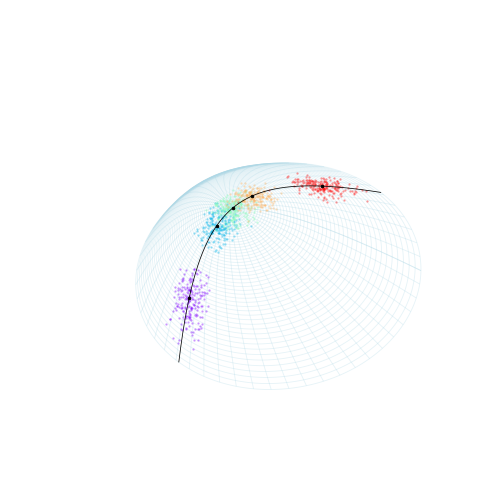


=== Creating sphere visualization ===


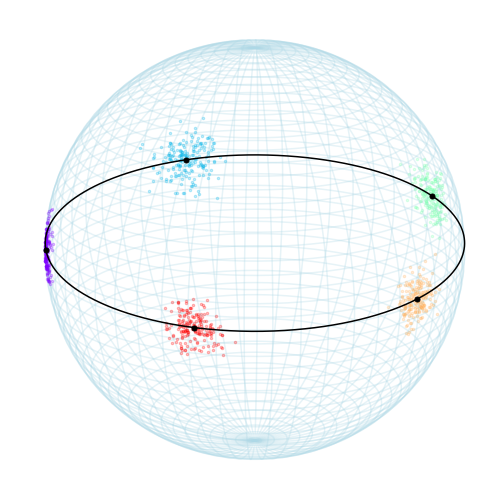


=== Creating SPD interpolation plot ===


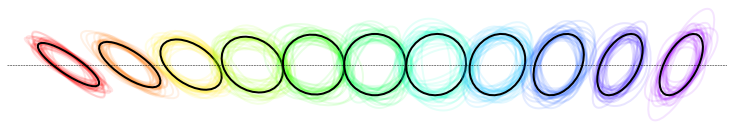


=== Creating sphere prediction balls ===


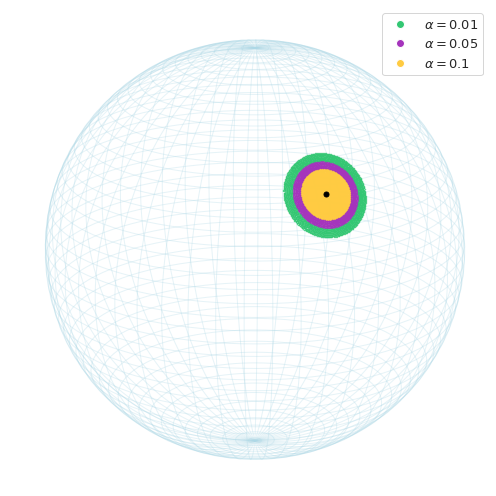


=== Creating hyperboloid prediction balls ===

=== Creating SPD ball visualizations ===
OOB prediction ball visualization using affine-invariant metric...


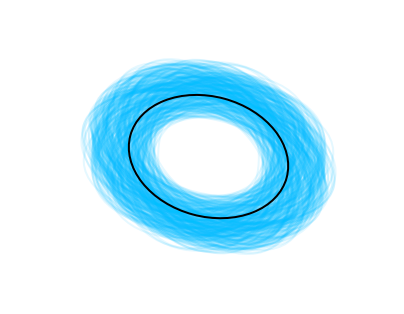

OOB prediction ball visualization using log-euclidean metric...


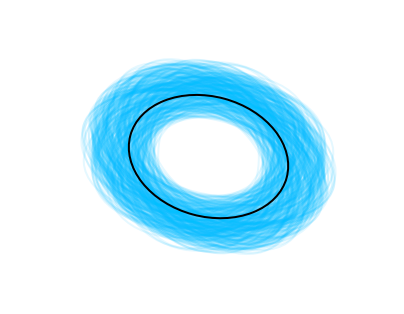

OOB prediction ball visualization using log-Cholesky metric...


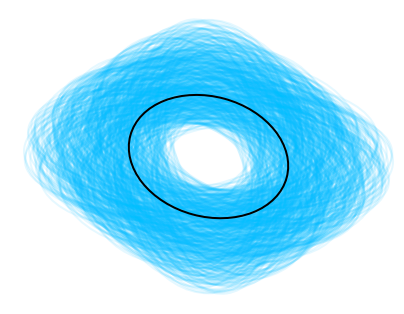

In [21]:
# 1. Hyperboloid visualization with regression curve and data points
# 2. Sphere visualization with regression curve and data points  
# 3. SPD matrices interpolation plot
# 4. Population prediction balls for sphere
# 5. Population prediction balls for hyperboloid

create_all_paper_plots()

# Fréchet means in the space of SPD matrices, for different metrics


--- Plot 1: d=15, q=2, different sigmas ---


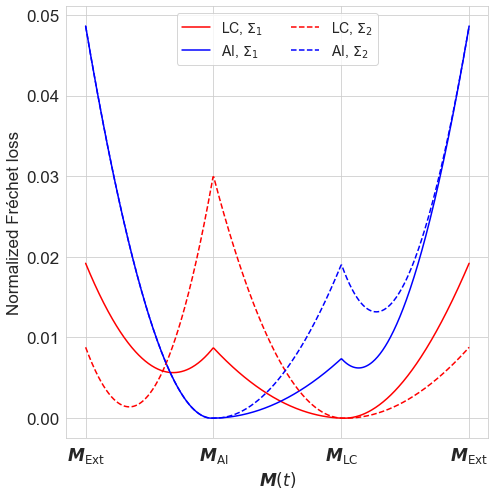


--- Plot 2: d=15, q=6, different sigmas ---


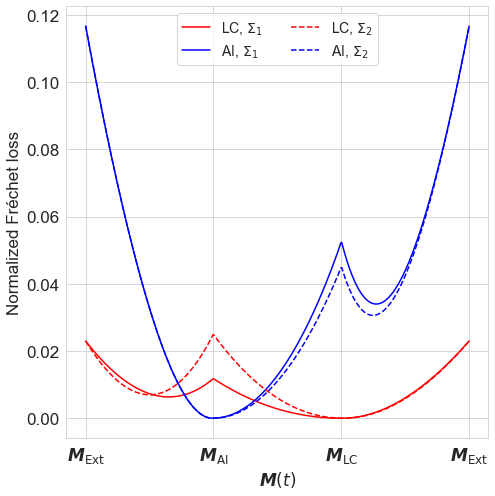


--- Plot 3: q=6, one sigma, different d values ---


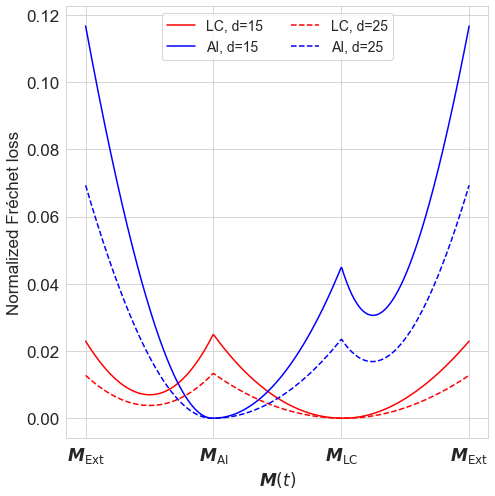

(<Figure size 504x504 with 1 Axes>,
 <Figure size 504x504 with 1 Axes>,
 <Figure size 504x504 with 1 Axes>)

In [2]:
# Generate the three SPD Fréchet mean analysis plots
# These plots compare log-Cholesky (LC) and affine-invariant (AI) metrics
# across different degrees of freedom and matrix dimensions
create_spd_frechet_plots()

# Fréchet random forests on the sphere

In [ ]:
frf = pd.read_csv("simulations_sphere/frf_results.csv")
display(frf.groupby(["n", "type", "level"])["coverage"].mean().unstack("level"))
display(frf.drop_duplicates(["case", "level"]).groupby(["n", "level"])["radius"].mean().unstack("level"))